# *Import Libraries*:-

In [2]:
# import pandas 
import pandas as pd
import numpy as np
from scipy import stats
import statistics as st
import seaborn as sns 
import matplotlib.pyplot as plt 


In [3]:
# load a specific dataset 
tips = sns.load_dataset("tips")
iris = sns.load_dataset("iris")

In [4]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [5]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [15]:
for i in tips.columns:
    if tips[i].dtype=='category':
        tips[i] = tips[i].replace("",None)
        tips[i] = tips[i].replace(" ",None)
    elif tips[i].dtype=='number':
        tips[i] = tips[i].replace("",np.nan)

In [16]:
tips.isnull().sum().any()

np.False_

In [17]:
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [21]:
tips[tips.duplicated()]

,total_bill,tip,sex,smoker,day,time,size
202,13.0,2.0,Female,Yes,Thur,Lunch,2


In [20]:
new_tips = tips.copy()

In [24]:
new_tips.drop_duplicates()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [25]:
new_tips.drop_duplicates(inplace=True)

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1889/1213572216.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_tips.drop_duplicates(inplace=True)


In [27]:
new_tips.duplicated().sum().any()

np.False_


# *Memory management:-*

In [36]:
for i in new_tips.columns:
    if new_tips[i].dtype=='category':
        new_tips[i] = pd.Categorical(new_tips[i])
    elif new_tips[i].dtype=='float':
        new_tips[i] = pd.to_numeric(new_tips[i],downcast='float')
    elif new_tips[i].dtype=='int':
        new_tips[i] = pd.to_numeric(new_tips[i],downcast='integer')

In [39]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [45]:
# rename , drop :-

new_tips.rename(columns={'sex':'gender','day':'Day'},inplace=True)


/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1889/710891549.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_tips.rename(columns={'sex':'gender','day':'Day'},inplace=True)


In [48]:
# create new columns :-
# 5% tax on total bill
new_tips['Final_bills'] = new_tips['total_bill'] + new_tips['total_bill'] * 0.05

In [49]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills
0,16.99,1.01,Female,No,Sun,Dinner,2,17.839500
1,10.34,1.66,Male,No,Sun,Dinner,3,10.857000
2,21.01,3.50,Male,No,Sun,Dinner,3,22.060501
3,23.68,3.31,Male,No,Sun,Dinner,2,24.864000
4,24.59,3.61,Female,No,Sun,Dinner,4,25.819500


In [50]:
new_tips['Double_of_tips'] = new_tips['tip'] * 2

In [51]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,Double_of_tips
0,16.99,1.01,Female,No,Sun,Dinner,2,17.839500,2.02
1,10.34,1.66,Male,No,Sun,Dinner,3,10.857000,3.32
2,21.01,3.50,Male,No,Sun,Dinner,3,22.060501,7.00
3,23.68,3.31,Male,No,Sun,Dinner,2,24.864000,6.62
4,24.59,3.61,Female,No,Sun,Dinner,4,25.819500,7.22


In [52]:
new_tips.drop(['Double_of_tips'],axis=1,inplace=True)

/var/folders/vl/5d3h1_r53791k9b7s8cvn6080000gn/T/ipykernel_1889/1572448243.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_tips.drop(['Double_of_tips'],axis=1,inplace=True)


In [53]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills
0,16.99,1.01,Female,No,Sun,Dinner,2,17.839500
1,10.34,1.66,Male,No,Sun,Dinner,3,10.857000
2,21.01,3.50,Male,No,Sun,Dinner,3,22.060501
3,23.68,3.31,Male,No,Sun,Dinner,2,24.864000
4,24.59,3.61,Female,No,Sun,Dinner,4,25.819500


In [62]:
# tital bill >= 20 , higher bill , 10-20 ( mid bill) , lowest bill
new_tips['bill_category'] = new_tips['Final_bills'].apply(
    lambda a: 'Highest bills' if a >= 20
    else ('Mid bills' if a >= 10
          else 'Lowest bills')
) 


In [63]:
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,No,Sun,Dinner,2,17.839500,Mid bills
1,10.34,1.66,Male,No,Sun,Dinner,3,10.857000,Mid bills
2,21.01,3.50,Male,No,Sun,Dinner,3,22.060501,Highest bills
3,23.68,3.31,Male,No,Sun,Dinner,2,24.864000,Highest bills
4,24.59,3.61,Female,No,Sun,Dinner,4,25.819500,Highest bills


In [67]:
new_tips['smoker'] = new_tips['smoker'].map({'NO':0,'Yes':1})
new_tips.head()

,total_bill,tip,gender,smoker,Day,time,size,Final_bills,bill_category
0,16.99,1.01,Female,NaN,Sun,Dinner,2,17.839500,Mid bills
1,10.34,1.66,Male,NaN,Sun,Dinner,3,10.857000,Mid bills
2,21.01,3.50,Male,NaN,Sun,Dinner,3,22.060501,Highest bills
3,23.68,3.31,Male,NaN,Sun,Dinner,2,24.864000,Highest bills
4,24.59,3.61,Female,NaN,Sun,Dinner,4,25.819500,Highest bills


In [65]:
new_tips.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 0 to 243
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   total_bill     243 non-null    float32 
 1   tip            243 non-null    float32 
 2   gender         243 non-null    category
 3   smoker         243 non-null    category
 4   Day            243 non-null    category
 5   time           243 non-null    category
 6   size           243 non-null    int8    
 7   Final_bills    243 non-null    float32 
 8   bill_category  243 non-null    str     
dtypes: category(4), float32(3), int8(1), str(1)
memory usage: 10.9 KB


<Axes: xlabel='Final_bills'>

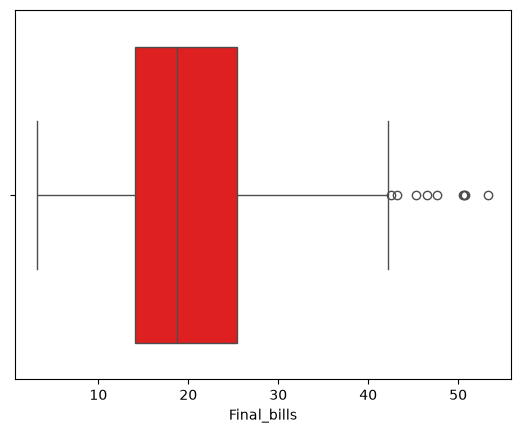

In [71]:
sns.boxplot(x = new_tips['Final_bills'],color='red')

In [ ]:
# create 

In [ ]:
# Sorting ,filter , group by :-


In [ ]:
# visulization :-
# merge or join two tables :-

In [6]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [10]:
tips.describe(include='number')

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [12]:
tips.describe(include='category')

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [7]:
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [13]:
iris.describe(include='str')

,species
count,150
unique,3
top,setosa
freq,50
